# Optical Transfer Function

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-06.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1, j0

In [2]:
%matplotlib inline

plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    'mathtext.fontset': 'stix',  # Use sans-serif for math text as well
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

plt.rcParams.update(plot_params)

## Define parameters

In [3]:
# --- 1. Setup Parameters and Arrays ---
a = 1.0
cutoff = 2 * a

# Create arrays for k (Analytical uses high res, Numerical uses points)
k2 = np.linspace(0, 2 * a, 300)
k_points = np.linspace(0, 2 * a, 20)

# Calculate OTF
otf_analytical = (2 / np.pi) * (np.arccos(k2/(2*a)) - (k2/(2*a)) * np.sqrt(1 -(k2/(2*a))**2))


# --- 3. Numerical Solution (Vectorized Integration) ---
# To avoid a loop, we broadcast 'k' against 'x' to create a 2D matrix.
# We interpret the integral as a sum (Trapezoidal rule).

# Create integration variable x (from small epsilon to 100 to approximate infinity)
x_grid = np.linspace(1e-5, 300, 4096) 

# Broadcast shapes:
# K needs to be column vector: (N, 1)
# X needs to be row vector:    (1, M)
K = k_points[:, np.newaxis]
X = x_grid[np.newaxis, :]

# Calculate the integrand on the huge 2D grid (20 rows x 5000 columns)
# integrand: (2 * BesselJ[1, a*x] / x)^2 * BesselJ[0, k*x] * x
integrand_matrix = (2 * j1(a * X) / X) ** 2 * j0(K * X) * X

# Integrate along the X-axis (axis 1) using trapezoidal rule
otf_numerical = np.trapezoid(integrand_matrix, x_grid, axis=1)
otf_numerical_normalized = otf_numerical / otf_numerical[0]  # normalize



## Plot

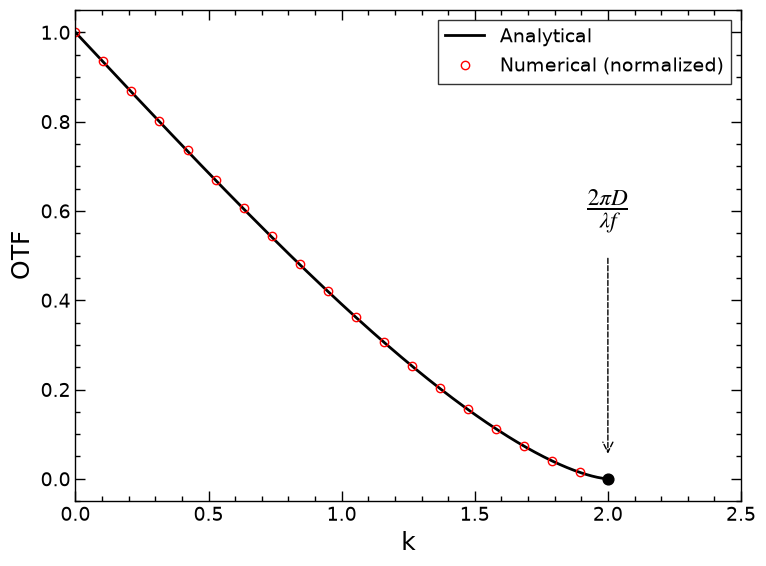

In [4]:
# --- 4. Plotting ---
fig1, ax1 = plt.subplots(figsize=(8, 6))
ax1 = plt.gca()

# Plot Analytical
ax1.plot(k2, otf_analytical, 'k-', linewidth=2, label='Analytical')

# Plot Numerical
ax1.plot(k_points, otf_numerical_normalized, 'ro', markerfacecolor='none', label='Numerical (normalized)')

# Annotations
ax1.scatter([2], [0], color='black', s=60, zorder=5)
ax1.annotate("", xy=(2, 0.05), xytext=(2, 0.5),
            arrowprops=dict(arrowstyle="->", linestyle="dashed", color="black"))
ax1.text(2, 0.55, r"$\frac{2\pi D}{\lambda f}$", 
        fontsize=24, ha='center', va='bottom')

# --- Formatting ---
ax1.set_xlabel("k", fontsize=18)
ax1.set_ylabel("OTF", fontsize=18)
ax1.set_xlim(0, 2.5)
ax1.set_ylim(-0.05, 1.05)
ax1.legend(loc='upper right', frameon=True, edgecolor='black', fancybox=False, fontsize=14)
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# Enable ticks on all sides and point them inward
ax1.tick_params(direction='in', top=True, right=True, which='both', labelsize=14)

plt.tight_layout()
plt.show()

## Coherent v. Incoherent

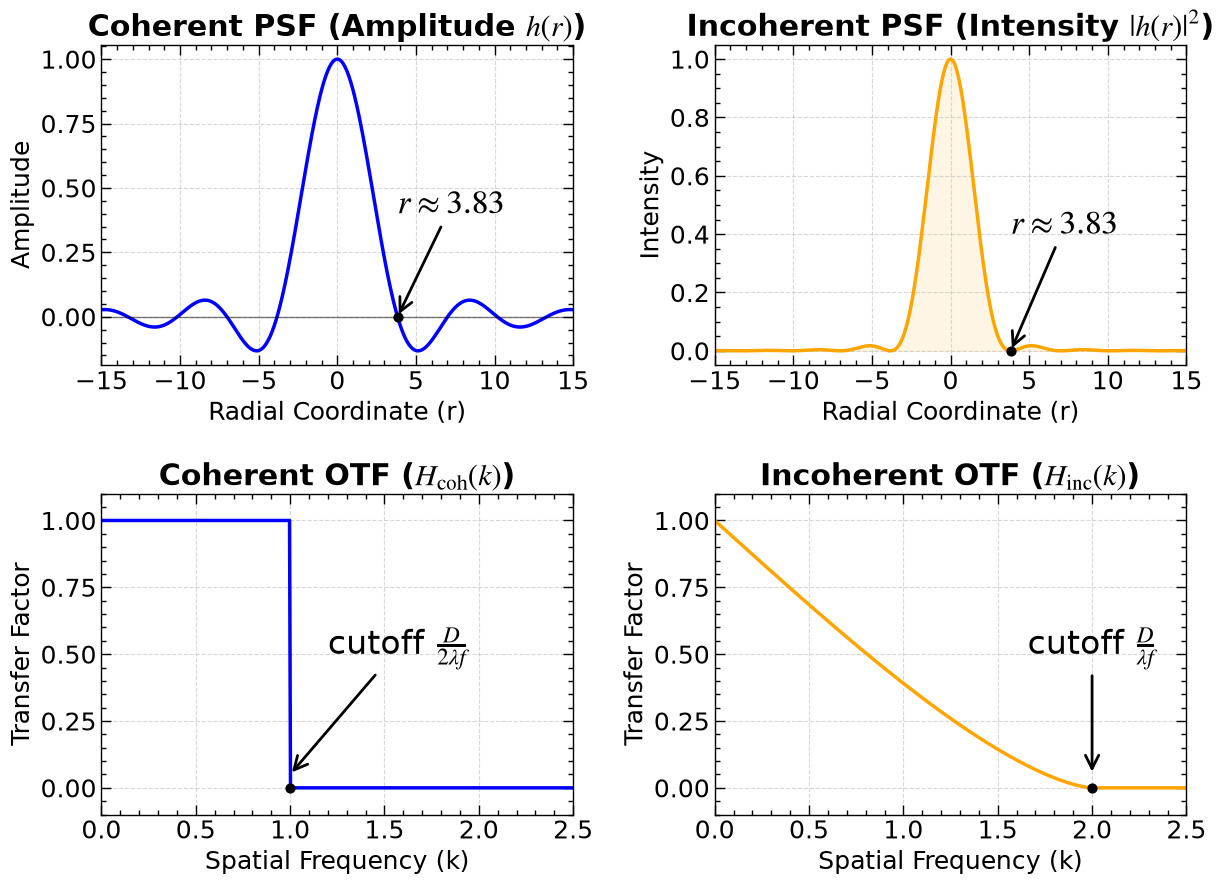

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1

# # --- 1. Style Setup ---
# plot_params = {
#     'font.size': 14,
#     'font.family': 'sans-serif',
#     'axes.linewidth': 1.2,
#     'lines.linewidth': 2.5,
#     'figure.figsize': (14, 10)
# }
# plt.rcParams.update(plot_params)

# --- 2. Data Calculation ---
# A. Spatial Frequency Grid (k)
k = np.linspace(0, 2.5, 500)
a5 = 1.0 # Radius parameter

# Coherent OTF: Step function (Cutoff at k=a5)
otf_coh = np.where(k <= a5, 1.0, 0.0)

# Incoherent OTF: Chat function (Cutoff at k=2a)
term = k / (2*a5)
term = np.clip(term, 0, 1)
otf_inc = np.where(k <= 2*a5, 
                   (2 / np.pi) * (np.arccos(term) - term * np.sqrt(1 - term**2)), 
                   0)

# B. Spatial Grid (Radial coordinate r)
# Zeros of J1(r) are at approx 3.83, 7.02, 10.17
r = np.linspace(-15, 15, 512)
r_safe = np.where(np.abs(r) < 1e-9, 1e-9, np.abs(r))

# Amplitude Impulse Response
# h(r) = 2 * J1(r) / r
amp = 2 * j1(r_safe) / r_safe

# Coherent PSF = Amplitude (can be negative)
psf_coh = amp 

# Incoherent PSF = Intensity (always positive)
psf_inc = amp**2

# --- 3. Plotting the 2x2 Grid ---
fig2, axes = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# ---------------------------------------------------------
# 1. Top-Left: Coherent PSF (Amplitude)
# ---------------------------------------------------------
ax5 = axes[0, 0]
ax5.plot(r, psf_coh, 'b')
ax5.set_title(r"Coherent PSF (Amplitude $h(r)$)", fontweight='bold')
ax5.set_xlabel("Radial Coordinate (r)")
ax5.set_ylabel("Amplitude")
ax5.axhline(0, color='black', linewidth=1, alpha=0.5)
ax5.grid(True, linestyle='--', alpha=0.5)
ax5.set_xlim(-15, 15)
ax5.minorticks_on()
ax5.tick_params(which='both',direction="in",width=1)
ax5.tick_params(which='major',length=7)
ax5.tick_params(which='minor',length=3.5)
ax5.xaxis.set_ticks_position('both')
ax5.yaxis.set_ticks_position('both')

# Label First Zero (3.83)
z1 = 3.8317
ax5.scatter([z1], [0], color='black', s=40, zorder=5)
ax5.annotate(r"$r \approx 3.83$", xy=(z1, 0), xytext=(z1, 0.4),
             arrowprops=dict(arrowstyle="->", color='black', linewidth=2), fontsize=24, ha='left')

# ---------------------------------------------------------
# 2. Top-Right: Incoherent PSF (Intensity)
# ---------------------------------------------------------
ax2 = axes[0, 1]
ax2.plot(r, psf_inc, 'orange')
ax2.set_title(r"Incoherent PSF (Intensity $|h(r)|^2$)", fontweight='bold')
ax2.set_xlabel("Radial Coordinate (r)")
ax2.set_ylabel("Intensity")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.set_xlim(-15, 15)
# Fill the Airy disk for effect
ax2.fill_between(r, 0, psf_inc, color='orange', alpha=0.1)
ax2.minorticks_on()
ax2.tick_params(which='both',direction="in",width=1)
ax2.tick_params(which='major',length=7)
ax2.tick_params(which='minor',length=3.5)
ax2.xaxis.set_ticks_position('both')
ax2.yaxis.set_ticks_position('both')

# Label First Zero (3.83) - The Airy Disk Radius
ax2.scatter([z1], [0], color='black', s=40, zorder=5)
ax2.annotate(r"$r \approx 3.83$", xy=(z1, 0), xytext=(z1, 0.4),
             arrowprops=dict(arrowstyle="->", color='black', linewidth=2), fontsize=24, ha='left')

# ---------------------------------------------------------
# 3. Bottom-Left: Coherent OTF
# ---------------------------------------------------------
ax3 = axes[1, 0]
ax3.plot(k, otf_coh, 'b')
ax3.set_title(r"Coherent OTF ($H_\mathrm{coh}(k)$)", fontweight='bold')
ax3.set_xlabel("Spatial Frequency (k)")
ax3.set_ylabel("Transfer Factor")
ax3.set_xlim(0, 2.5)
ax3.set_ylim(-0.1, 1.1)
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.minorticks_on()
ax3.tick_params(which='both',direction="in",width=1)
ax3.tick_params(which='major',length=7)
ax3.tick_params(which='minor',length=3.5)
ax3.xaxis.set_ticks_position('both')
ax3.yaxis.set_ticks_position('both')

# Annotation: Coherent Cutoff
ax3.scatter([1.0], [0], color='black', s=40, zorder=5)
ax3.annotate(r"cutoff $\frac{D}{2\lambda f}$", 
             xy=(1.0, 0.05), xytext=(1.2, 0.5),
             arrowprops=dict(arrowstyle="->", color='black', linewidth=2),
             fontsize=24, ha='left')

# ---------------------------------------------------------
# 4. Bottom-Right: Incoherent OTF
# ---------------------------------------------------------
ax4 = axes[1, 1]
ax4.plot(k, otf_inc, 'orange')
ax4.set_title(r"Incoherent OTF ($H_\mathrm{inc}(k)$)", fontweight='bold')
ax4.set_xlabel("Spatial Frequency (k)")
ax4.set_ylabel("Transfer Factor")
ax4.set_xlim(0, 2.5)
ax4.set_ylim(-0.1, 1.1)
ax4.grid(True, linestyle='--', alpha=0.5)
ax4.minorticks_on()
ax4.tick_params(which='both',direction="in",width=1)
ax4.tick_params(which='major',length=7)
ax4.tick_params(which='minor',length=3.5)
ax4.xaxis.set_ticks_position('both')
ax4.yaxis.set_ticks_position('both')

# Annotation: Incoherent Cutoff
ax4.scatter([2.0], [0], color='black', s=40, zorder=5)
ax4.annotate(r"cutoff $\frac{D}{\lambda f}$", 
             xy=(2.0, 0.05), xytext=(2.0, 0.5),
             arrowprops=dict(arrowstyle="->", color='black', linewidth=2),
             fontsize=24, ha='center')

# plt.suptitle("Circular Aperture: Coherent vs. Incoherent Imaging", fontsize=18, y=0.98)
plt.show()